In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("indian_liver_patient.csv")

print(df.shape)
df.head()

(583, 11)


,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Dataset
0,65,Female,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1


In [4]:
df.columns

Index(['Age', 'Gender', 'Total_Bilirubin', 'Direct_Bilirubin',
       'Alkaline_Phosphotase', 'Alamine_Aminotransferase',
       'Aspartate_Aminotransferase', 'Total_Protiens', 'Albumin',
       'Albumin_and_Globulin_Ratio', 'Dataset'],
      dtype='object')

In [5]:
df.isnull().sum()

Age                           0
Gender                        0
Total_Bilirubin               0
Direct_Bilirubin              0
Alkaline_Phosphotase          0
Alamine_Aminotransferase      0
Aspartate_Aminotransferase    0
Total_Protiens                0
Albumin                       0
Albumin_and_Globulin_Ratio    4
Dataset                       0
dtype: int64

In [6]:
print("\nDuplicate rows:", df.duplicated().sum())


Duplicate rows: 13


In [7]:
df = df.drop_duplicates()

In [8]:
print("New shape:", df.shape)
print("Duplicates:", df.duplicated().sum())

New shape: (570, 11)
Duplicates: 0


In [9]:
df.isnull().sum()

Age                           0
Gender                        0
Total_Bilirubin               0
Direct_Bilirubin              0
Alkaline_Phosphotase          0
Alamine_Aminotransferase      0
Aspartate_Aminotransferase    0
Total_Protiens                0
Albumin                       0
Albumin_and_Globulin_Ratio    4
Dataset                       0
dtype: int64

In [10]:
df[df["Albumin_and_Globulin_Ratio"].isnull()]

,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Dataset
209,45,Female,0.9,0.3,189,23,33,6.6,3.9,NaN,1
241,51,Male,0.8,0.2,230,24,46,6.5,3.1,NaN,1
253,35,Female,0.6,0.2,180,12,15,5.2,2.7,NaN,2
312,27,Male,1.3,0.6,106,25,54,8.5,4.8,NaN,2


In [11]:
df["Albumin_and_Globulin_Ratio"].describe()

count    566.000000
mean       0.948004
std        0.319635
min        0.300000
25%        0.700000
50%        0.950000
75%        1.100000
max        2.800000
Name: Albumin_and_Globulin_Ratio, dtype: float64

In [12]:
df["Albumin_and_Globulin_Ratio"] = df["Albumin_and_Globulin_Ratio"].fillna(
    df["Albumin_and_Globulin_Ratio"].median()
)

In [13]:
df[df["Albumin_and_Globulin_Ratio"].isnull()]

,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Dataset


In [14]:
print(df["Albumin_and_Globulin_Ratio"].isnull().sum())

0


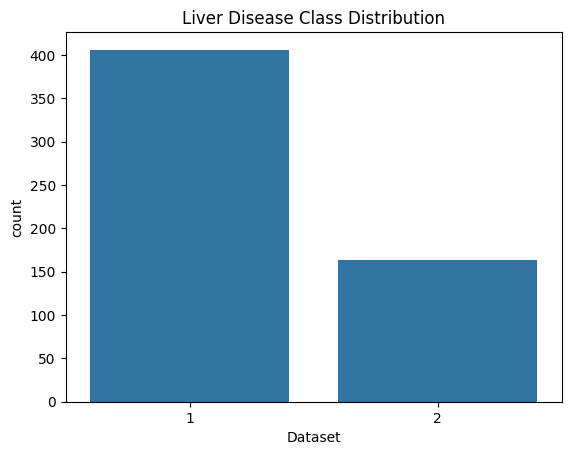

In [15]:
sns.countplot(x="Dataset", data=df)
plt.title("Liver Disease Class Distribution")
plt.show()

In [16]:
print(df["Dataset"].value_counts())
print(df["Dataset"].value_counts(normalize=True) * 100)

Dataset
1    406
2    164
Name: count, dtype: int64
Dataset
1    71.22807
2    28.77193
Name: proportion, dtype: float64


In [17]:
print(df["Gender"].value_counts())

Gender
Male      430
Female    140
Name: count, dtype: int64


In [18]:
print(df["Gender"].value_counts(normalize=True) * 100)

Gender
Male      75.438596
Female    24.561404
Name: proportion, dtype: float64


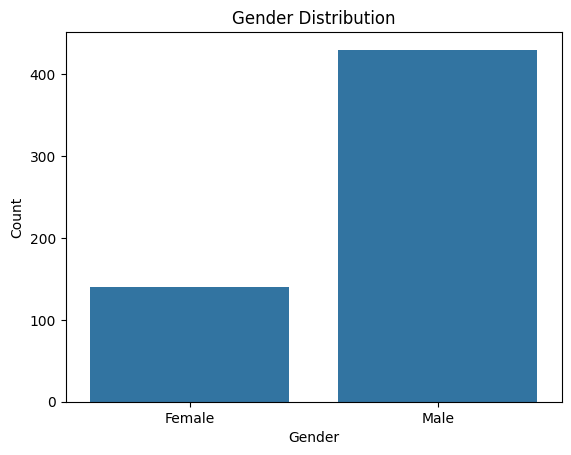

In [19]:
sns.countplot(x="Gender", data=df)
plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.show()

In [20]:
pd.crosstab(df["Gender"], df["Dataset"])

Dataset,1,2
Gender,,
Female,91,49
Male,315,115


In [21]:
pd.crosstab(
    df["Gender"],
    df["Dataset"],
    normalize="index"
) * 100

Dataset,1,2
Gender,,
Female,65.000000,35.000000
Male,73.255814,26.744186


In [22]:
print(df["Age"].describe())

count    570.000000
mean      44.849123
std       16.242182
min        4.000000
25%       33.000000
50%       45.000000
75%       58.000000
max       90.000000
Name: Age, dtype: float64


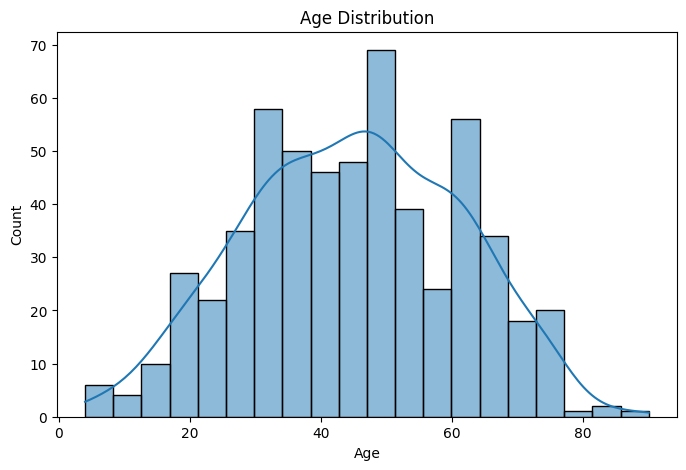

In [23]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Age", bins=20, kde=True)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

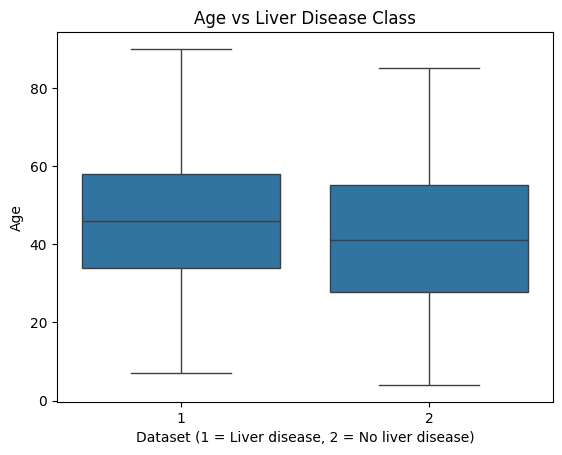

In [24]:
sns.boxplot(data=df, x="Dataset", y="Age")
plt.title("Age vs Liver Disease Class")
plt.xlabel("Dataset (1 = Liver disease, 2 = No liver disease)")
plt.ylabel("Age")
plt.show()

In [25]:
df["Dataset"] = df["Dataset"].map({1: 1, 2: 0})

In [26]:
print(df["Dataset"].value_counts())

Dataset
1    406
0    164
Name: count, dtype: int64


In [27]:
df.groupby("Dataset")["Age"].describe()

,count,mean,std,min,25%,50%,75%,max
Dataset,,,,,,,,
0,164.0,41.323171,17.143185,4.0,27.75,41.0,55.25,85.0
1,406.0,46.273399,15.661595,7.0,34.00,46.0,58.00,90.0


In [28]:
df.groupby("Dataset")["Total_Bilirubin"].describe()

,count,mean,std,min,25%,50%,75%,max
Dataset,,,,,,,,
0,164.0,1.110366,0.952209,0.5,0.7,0.8,1.100,7.3
1,406.0,4.215025,7.214628,0.4,0.8,1.4,3.675,75.0


In [29]:
df.groupby("Dataset")["Direct_Bilirubin"].describe()

,count,mean,std,min,25%,50%,75%,max
Dataset,,,,,,,,
0,164.0,0.381098,0.497918,0.1,0.2,0.2,0.3,3.6
1,406.0,1.948522,3.235633,0.1,0.2,0.5,1.8,19.7


In [30]:
df.groupby("Dataset")["Alkaline_Phosphotase"].describe()

,count,mean,std,min,25%,50%,75%,max
Dataset,,,,,,,,
0,164.0,219.426829,141.290939,90.0,162.0,186.5,212.0,1580.0
1,406.0,320.965517,271.153419,63.0,186.0,229.0,319.0,2110.0


In [31]:
df.groupby("Dataset")["Alamine_Aminotransferase"].describe()

,count,mean,std,min,25%,50%,75%,max
Dataset,,,,,,,,
0,164.0,33.536585,25.208673,10.0,20.0,27.0,37.25,181.0
1,406.0,98.386700,211.656875,12.0,25.0,40.5,75.75,2000.0


In [32]:
df.groupby("Dataset")["Aspartate_Aminotransferase"].describe()

,count,mean,std,min,25%,50%,75%,max
Dataset,,,,,,,,
0,164.0,40.286585,36.499898,10.0,21.0,29.0,43.00,285.0
1,406.0,137.290640,340.034964,11.0,29.0,51.0,107.25,4929.0


In [33]:
df.groupby("Dataset")["Total_Protiens"].describe()

,count,mean,std,min,25%,50%,75%,max
Dataset,,,,,,,,
0,164.0,6.560976,1.063246,3.7,5.900,6.65,7.3,9.2
1,406.0,6.470197,1.098472,2.7,5.725,6.60,7.2,9.6


In [34]:
df.groupby("Dataset")["Albumin"].describe()

,count,mean,std,min,25%,50%,75%,max
Dataset,,,,,,,,
0,164.0,3.357927,0.783024,1.4,2.9,3.45,4.000,5.0
1,406.0,3.064532,0.787666,0.9,2.5,3.00,3.675,5.5


In [35]:
df.groupby("Dataset")["Albumin_and_Globulin_Ratio"].describe()

,count,mean,std,min,25%,50%,75%,max
Dataset,,,,,,,,
0,164.0,1.033415,0.284664,0.37,0.9,1.0,1.2,1.9
1,406.0,0.913522,0.325222,0.30,0.7,0.9,1.1,2.8


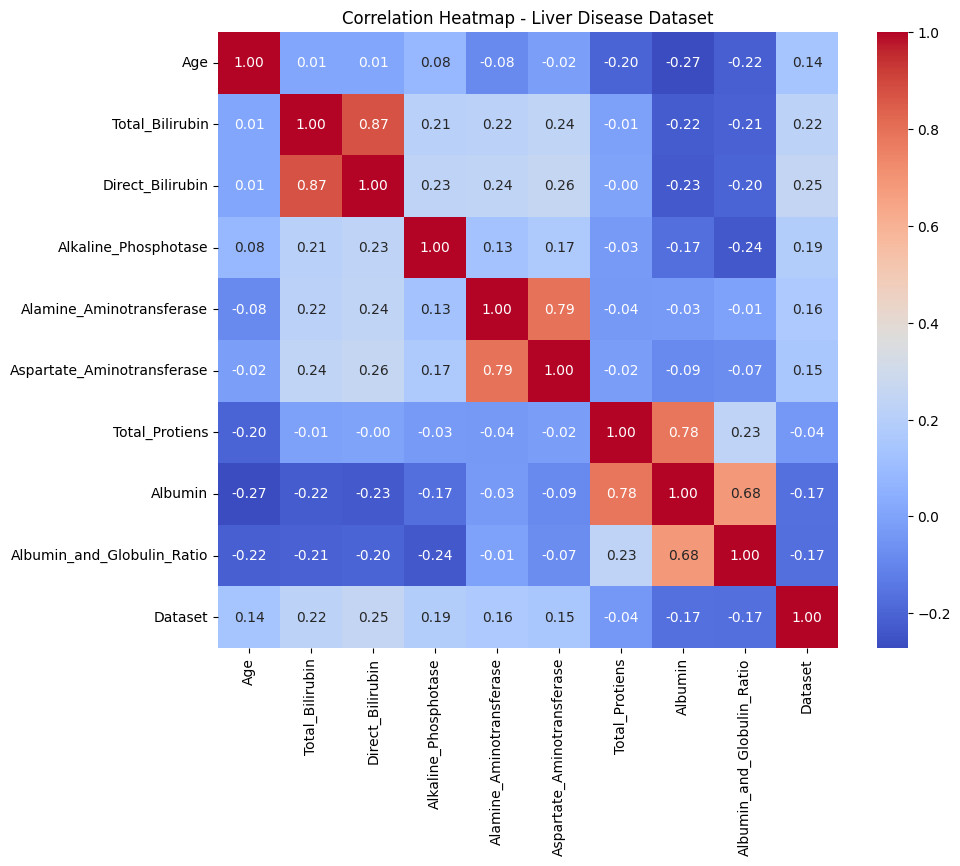

In [36]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap - Liver Disease Dataset")
plt.show()

In [37]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 570 entries, 0 to 582
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         570 non-null    int64  
 1   Gender                      570 non-null    object 
 2   Total_Bilirubin             570 non-null    float64
 3   Direct_Bilirubin            570 non-null    float64
 4   Alkaline_Phosphotase        570 non-null    int64  
 5   Alamine_Aminotransferase    570 non-null    int64  
 6   Aspartate_Aminotransferase  570 non-null    int64  
 7   Total_Protiens              570 non-null    float64
 8   Albumin                     570 non-null    float64
 9   Albumin_and_Globulin_Ratio  570 non-null    float64
 10  Dataset                     570 non-null    int64  
dtypes: float64(5), int64(5), object(1)
memory usage: 53.4+ KB


In [38]:
X = df.drop("Dataset", axis=1)
y = df["Dataset"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())

X shape: (570, 10)
y shape: (570,)

Target distribution:
Dataset
1    406
0    164
Name: count, dtype: int64


In [40]:
X = df.drop("Dataset", axis=1)
y = df["Dataset"]
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [41]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

num_cols = X.select_dtypes(include="number").columns
cat_cols = ["Gender"]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])

In [42]:
from sklearn.linear_model import LogisticRegression

lr_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

lr_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers co

In [45]:
y_pred = lr_model.predict(X_test)
y_prob = lr_model.predict_proba(X_test)[:, 1]

In [46]:
from sklearn.metrics import *

results_df = pd.DataFrame([{
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1": f1_score(y_test, y_pred),
    "F2": fbeta_score(y_test, y_pred, beta=2),
    "ROC_AUC": roc_auc_score(y_test, y_prob)
}])

results_df.round(4)

,Model,Accuracy,Precision,Recall,F1,F2,ROC_AUC
0,Logistic Regression,0.7105,0.7449,0.9012,0.8156,0.8649,0.8036


In [47]:
from sklearn.tree import DecisionTreeClassifier

dt_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(random_state=42))
])

dt_model.fit(X_train, y_train)

y_pred = dt_model.predict(X_test)
y_prob = dt_model.predict_proba(X_test)[:, 1]

In [48]:
dt_results = {
    "Model": "Decision Tree",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1": f1_score(y_test, y_pred, zero_division=0),
    "F2": fbeta_score(y_test, y_pred, beta=2, zero_division=0),
    "ROC_AUC": roc_auc_score(y_test, y_prob)
}

results_df.loc[len(results_df)] = dt_results

results_df.round(4)

,Model,Accuracy,Precision,Recall,F1,F2,ROC_AUC
0,Logistic Regression,0.7105,0.7449,0.9012,0.8156,0.8649,0.8036
1,Decision Tree,0.6316,0.7407,0.7407,0.7407,0.7407,0.5522


In [49]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "model__max_depth": [3, 5, 10, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 5],
    "model__class_weight": [None, "balanced"]
}

grid_dt = GridSearchCV(
    dt_model,
    param_grid,
    cv=5,
    scoring="recall",
    n_jobs=-1
)

grid_dt.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__class_weight': [None, 'balanced'], 'model__max_depth': [3, 5, ...], 'model__min_samples_leaf': [1, 2, ...], 'model__min_samples_split': [2, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'recall'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the comput

In [50]:
print(grid_dt.best_params_)
print("Best CV Recall:", grid_dt.best_score_)

{'model__class_weight': None, 'model__max_depth': 3, 'model__min_samples_leaf': 1, 'model__min_samples_split': 10}
Best CV Recall: 0.8861538461538462


In [52]:
dt_tuned = grid_dt.best_estimator_
y_pred = dt_tuned.predict(X_test)
y_prob = dt_tuned.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.56      0.42      0.48        33
           1       0.79      0.86      0.82        81

    accuracy                           0.74       114
   macro avg       0.67      0.64      0.65       114
weighted avg       0.72      0.74      0.72       114



In [53]:
dt_tuned_results = {
    "Model": "Decision Tree (Tuned)",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1": f1_score(y_test, y_pred, zero_division=0),
    "F2": fbeta_score(y_test, y_pred, beta=2, zero_division=0),
    "ROC_AUC": roc_auc_score(y_test, y_prob)
}

results_df.loc[len(results_df)] = dt_tuned_results
results_df

,Model,Accuracy,Precision,Recall,F1,F2,ROC_AUC
0,Logistic Regression,0.710526,0.744898,0.901235,0.815642,0.864929,0.803591
1,Decision Tree,0.631579,0.740741,0.740741,0.740741,0.740741,0.552189
2,Decision Tree (Tuned),0.736842,0.786517,0.864198,0.823529,0.847458,0.754583


In [54]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(random_state=42))
])

rf_model.fit(X_train, y_train)

y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, 1]

In [55]:
rf_results = {
    "Model": "Random Forest",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1": f1_score(y_test, y_pred, zero_division=0),
    "F2": fbeta_score(y_test, y_pred, beta=2, zero_division=0),
    "ROC_AUC": roc_auc_score(y_test, y_prob)
}

results_df.loc[len(results_df)] = rf_results
results_df

,Model,Accuracy,Precision,Recall,F1,F2,ROC_AUC
0,Logistic Regression,0.710526,0.744898,0.901235,0.815642,0.864929,0.803591
1,Decision Tree,0.631579,0.740741,0.740741,0.740741,0.740741,0.552189
2,Decision Tree (Tuned),0.736842,0.786517,0.864198,0.823529,0.847458,0.754583
3,Random Forest,0.754386,0.767677,0.938272,0.844444,0.898345,0.760569


In [56]:
param_grid_rf = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2],
    "model__class_weight": [None, "balanced"]
}

In [57]:
from sklearn.model_selection import GridSearchCV

grid_rf = GridSearchCV(
    rf_model,
    param_grid_rf,
    cv=5,
    scoring="recall",
    n_jobs=-1
)

grid_rf.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__class_weight': [None, 'balanced'], 'model__max_depth': [None, 10, ...], 'model__min_samples_leaf': [1, 2], 'model__min_samples_split': [2, 5], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'recall'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computa

In [58]:
print("Best Parameters:", grid_rf.best_params_)
print("Best CV Recall:", grid_rf.best_score_)

Best Parameters: {'model__class_weight': 'balanced', 'model__max_depth': 20, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 100}
Best CV Recall: 0.8676923076923078


In [59]:
rf_tuned = grid_rf.best_estimator_

y_pred = rf_tuned.predict(X_test)
y_prob = rf_tuned.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.60      0.18      0.28        33
           1       0.74      0.95      0.83        81

    accuracy                           0.73       114
   macro avg       0.67      0.57      0.56       114
weighted avg       0.70      0.73      0.67       114



In [60]:
rf_tuned_results = {
    "Model": "Random Forest (Tuned)",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1": f1_score(y_test, y_pred, zero_division=0),
    "F2": fbeta_score(y_test, y_pred, beta=2, zero_division=0),
    "ROC_AUC": roc_auc_score(y_test, y_prob)
}

results_df.loc[len(results_df)] = rf_tuned_results
results_df

,Model,Accuracy,Precision,Recall,F1,F2,ROC_AUC
0,Logistic Regression,0.710526,0.744898,0.901235,0.815642,0.864929,0.803591
1,Decision Tree,0.631579,0.740741,0.740741,0.740741,0.740741,0.552189
2,Decision Tree (Tuned),0.736842,0.786517,0.864198,0.823529,0.847458,0.754583
3,Random Forest,0.754386,0.767677,0.938272,0.844444,0.898345,0.760569
4,Random Forest (Tuned),0.728070,0.740385,0.950617,0.832432,0.899533,0.754209


In [61]:
from sklearn.ensemble import GradientBoostingClassifier

gb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", GradientBoostingClassifier(random_state=42))
])

gb_model.fit(X_train, y_train)

y_pred = gb_model.predict(X_test)
y_prob = gb_model.predict_proba(X_test)[:, 1]

In [62]:
gb_results = {
    "Model": "Gradient Boosting",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1": f1_score(y_test, y_pred, zero_division=0),
    "F2": fbeta_score(y_test, y_pred, beta=2, zero_division=0),
    "ROC_AUC": roc_auc_score(y_test, y_prob)
}

results_df.loc[len(results_df)] = gb_results
results_df

,Model,Accuracy,Precision,Recall,F1,F2,ROC_AUC
0,Logistic Regression,0.710526,0.744898,0.901235,0.815642,0.864929,0.803591
1,Decision Tree,0.631579,0.740741,0.740741,0.740741,0.740741,0.552189
2,Decision Tree (Tuned),0.736842,0.786517,0.864198,0.823529,0.847458,0.754583
3,Random Forest,0.754386,0.767677,0.938272,0.844444,0.898345,0.760569
4,Random Forest (Tuned),0.728070,0.740385,0.950617,0.832432,0.899533,0.754209
5,Gradient Boosting,0.728070,0.735849,0.962963,0.834225,0.906977,0.763187


In [63]:
param_grid_gb = {
    "model__n_estimators": [100, 200],
    "model__learning_rate": [0.03, 0.1],
    "model__max_depth": [2, 3],
    "model__min_samples_split": [5, 10],
    "model__min_samples_leaf": [2, 5]
}


In [64]:
grid_gb = GridSearchCV(
    gb_model,
    param_grid_gb,
    cv=5,
    scoring="recall",
    n_jobs=-1
)

grid_gb.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__learning_rate': [0.03, 0.1], 'model__max_depth': [2, 3], 'model__min_samples_leaf': [2, 5], 'model__min_samples_split': [5, 10], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'recall'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for 

In [65]:
print("Best Parameters:", grid_gb.best_params_)
print("Best CV Recall:", grid_gb.best_score_)

Best Parameters: {'model__learning_rate': 0.03, 'model__max_depth': 2, 'model__min_samples_leaf': 2, 'model__min_samples_split': 5, 'model__n_estimators': 100}
Best CV Recall: 0.9199999999999999


In [66]:
gb_tuned = grid_gb.best_estimator_

y_pred = gb_tuned.predict(X_test)
y_prob = gb_tuned.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.83      0.15      0.26        33
           1       0.74      0.99      0.85        81

    accuracy                           0.75       114
   macro avg       0.79      0.57      0.55       114
weighted avg       0.77      0.75      0.68       114



In [67]:
gb_tuned_results = {
    "Model": "Gradient Boosting (Tuned)",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1": f1_score(y_test, y_pred, zero_division=0),
    "F2": fbeta_score(y_test, y_pred, beta=2, zero_division=0),
    "ROC_AUC": roc_auc_score(y_test, y_prob)
}

results_df.loc[len(results_df)] = gb_tuned_results
results_df

,Model,Accuracy,Precision,Recall,F1,F2,ROC_AUC
0,Logistic Regression,0.710526,0.744898,0.901235,0.815642,0.864929,0.803591
1,Decision Tree,0.631579,0.740741,0.740741,0.740741,0.740741,0.552189
2,Decision Tree (Tuned),0.736842,0.786517,0.864198,0.823529,0.847458,0.754583
3,Random Forest,0.754386,0.767677,0.938272,0.844444,0.898345,0.760569
4,Random Forest (Tuned),0.728070,0.740385,0.950617,0.832432,0.899533,0.754209
5,Gradient Boosting,0.728070,0.735849,0.962963,0.834225,0.906977,0.763187
6,Gradient Boosting (Tuned),0.745614,0.740741,0.987654,0.846561,0.925926,0.801160


In [68]:
from xgboost import XGBClassifier

In [69]:
xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42,
        eval_metric="logloss"
    ))
])

xgb_model.fit(X_train, y_train)

y_pred = xgb_model.predict(X_test)
y_prob = xgb_model.predict_proba(X_test)[:, 1]

In [70]:
xgb_results = {
    "Model": "XGBoost",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1": f1_score(y_test, y_pred, zero_division=0),
    "F2": fbeta_score(y_test, y_pred, beta=2, zero_division=0),
    "ROC_AUC": roc_auc_score(y_test, y_prob)
}

results_df.loc[len(results_df)] = xgb_results
results_df

,Model,Accuracy,Precision,Recall,F1,F2,ROC_AUC
0,Logistic Regression,0.710526,0.744898,0.901235,0.815642,0.864929,0.803591
1,Decision Tree,0.631579,0.740741,0.740741,0.740741,0.740741,0.552189
2,Decision Tree (Tuned),0.736842,0.786517,0.864198,0.823529,0.847458,0.754583
3,Random Forest,0.754386,0.767677,0.938272,0.844444,0.898345,0.760569
4,Random Forest (Tuned),0.728070,0.740385,0.950617,0.832432,0.899533,0.754209
5,Gradient Boosting,0.728070,0.735849,0.962963,0.834225,0.906977,0.763187
6,Gradient Boosting (Tuned),0.745614,0.740741,0.987654,0.846561,0.925926,0.801160
7,XGBoost,0.710526,0.726415,0.950617,0.823529,0.895349,0.747849


In [71]:
param_grid_xgb = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [2, 3],
    "model__learning_rate": [0.03, 0.1],
    "model__subsample": [0.8, 1.0]
}

In [72]:
grid_xgb = GridSearchCV(
    xgb_model,
    param_grid_xgb,
    cv=5,
    scoring="recall",
    n_jobs=-1
)

grid_xgb.fit(X_train, y_train)


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__learning_rate': [0.03, 0.1], 'model__max_depth': [2, 3], 'model__n_estimators': [100, 200], 'model__subsample': [0.8, 1.0]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'recall'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fol

In [73]:
print("Best Parameters:", grid_xgb.best_params_)
print("Best CV Recall:", grid_xgb.best_score_)

Best Parameters: {'model__learning_rate': 0.03, 'model__max_depth': 2, 'model__n_estimators': 100, 'model__subsample': 1.0}
Best CV Recall: 0.9199999999999999


In [74]:
xgb_tuned = grid_xgb.best_estimator_

y_pred = xgb_tuned.predict(X_test)
y_prob = xgb_tuned.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.60      0.09      0.16        33
           1       0.72      0.98      0.83        81

    accuracy                           0.72       114
   macro avg       0.66      0.53      0.49       114
weighted avg       0.69      0.72      0.64       114



In [82]:
xgb_tuned_results = {
    "Model": "XGBoost (Tuned)",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1": f1_score(y_test, y_pred, zero_division=0),
    "F2": fbeta_score(y_test, y_pred, beta=2, zero_division=0),
    "ROC_AUC": roc_auc_score(y_test, y_prob)
}

results_df.loc[len(results_df)] = xgb_tuned_results
results_df

,Model,Accuracy,Precision,Recall,F1,F2,ROC_AUC
0,Logistic Regression,0.710526,0.744898,0.901235,0.815642,0.864929,0.803591
1,Decision Tree,0.631579,0.740741,0.740741,0.740741,0.740741,0.552189
2,Decision Tree (Tuned),0.736842,0.786517,0.864198,0.823529,0.847458,0.754583
3,Random Forest,0.754386,0.767677,0.938272,0.844444,0.898345,0.760569
4,Random Forest (Tuned),0.728070,0.740385,0.950617,0.832432,0.899533,0.754209
5,Gradient Boosting,0.728070,0.735849,0.962963,0.834225,0.906977,0.763187
6,Gradient Boosting (Tuned),0.745614,0.740741,0.987654,0.846561,0.925926,0.801160
7,XGBoost,0.710526,0.726415,0.950617,0.823529,0.895349,0.747849
8,XGBoost (Tuned),0.719298,0.724771,0.975309,0.831579,0.912240,0.793865
9,XGBoost (Tuned),0.719298,0.716814,1.000000,0.835052,0.926773,0.793865
